In [1]:
import pandas as pd
import joblib

# Reload our data splits
X_train = pd.read_csv("data/processed/X_train.csv")
X_test = pd.read_csv("data/processed/X_test.csv")
y_train = pd.read_csv("data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("data/processed/y_test.csv").squeeze()

# Reload our trained, calibrated model
calibrated_model = joblib.load("models/xgb_calibrated_model.pkl")

print("Everything loaded successfully!")
print("X_test shape:", X_test.shape)

Everything loaded successfully!
X_test shape: (269098, 60)


In [6]:
# Unwrap both layers in one go, then immediately create the explainer
frozen_estimator = calibrated_model.calibrated_classifiers_[0].estimator
xgb_model_for_shap = frozen_estimator.estimator

print("Type check:", type(xgb_model_for_shap))

explainer = shap.TreeExplainer(xgb_model_for_shap)
print("Explainer created successfully!")

Type check: <class 'xgboost.sklearn.XGBClassifier'>
Explainer created successfully!


In [7]:
# Calculate SHAP values for the first 100 test examples (fast, good for exploring)
X_test_sample = X_test.iloc[:100]

shap_values = explainer.shap_values(X_test_sample)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (100, 60)


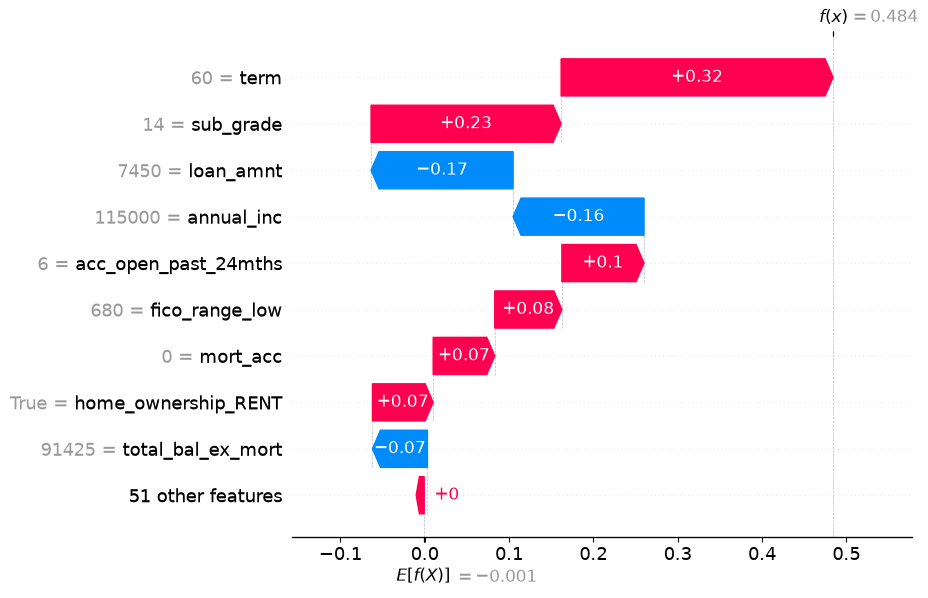

In [8]:
import shap

# Visualize the explanation for the first applicant in our sample
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0], 
        base_values=explainer.expected_value, 
        data=X_test_sample.iloc[0],
        feature_names=X_test_sample.columns.tolist()
    )
)

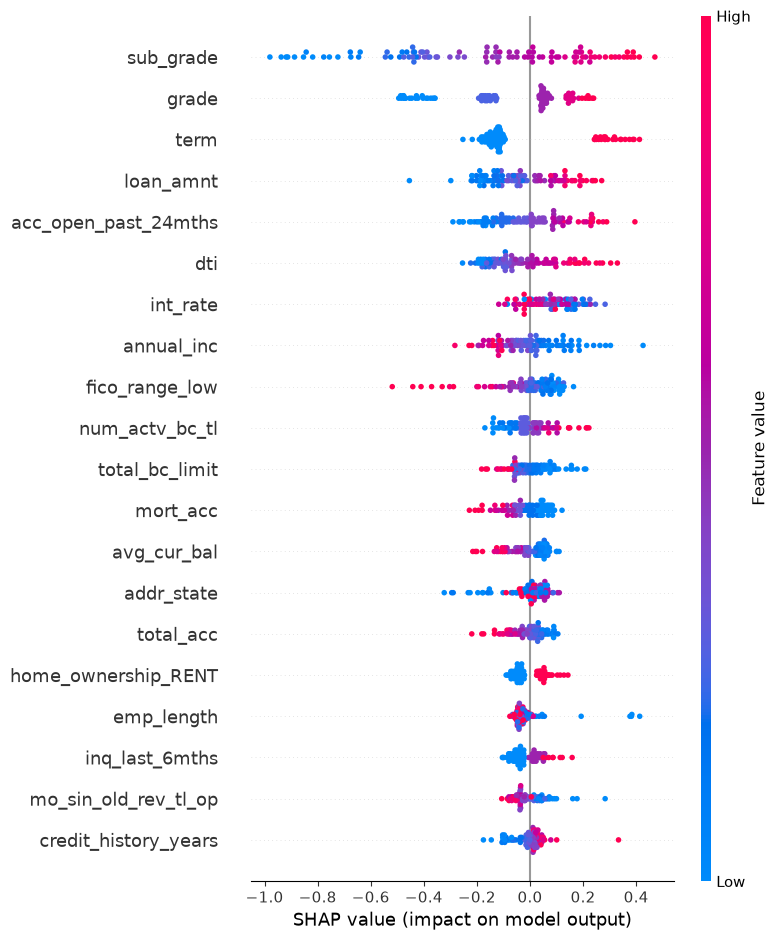

In [9]:
shap.summary_plot(shap_values, X_test_sample, feature_names=X_test_sample.columns.tolist())

In [10]:
import numpy as np
np.save("models/shap_values_sample.npy", shap_values)
print("SHAP values saved!")

SHAP values saved!
